<a href="https://colab.research.google.com/github/prabhnoor14/walmart-hurricane-project/blob/main/2026_10_30_%E2%80%94_Midterm_Progress_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import requests

base_url = 'https://raw.githubusercontent.com/prabhnoor14/walmart-hurricane-project/main/data/'

walmart_transactions_copy = pd.read_csv(
    base_url + 'walmart_transactions.csv'
).drop_duplicates().copy()

walmart_transactions_copy['timestamp'] = pd.to_datetime(
    walmart_transactions_copy['timestamp'],
    format='mixed',
    errors='coerce'
)

walmart_transactions_copy['transaction_date'] = (
    walmart_transactions_copy['timestamp'].dt.normalize()
)

def clean_store_id(col):
    col = col.astype(str).str.strip().str.upper()
    col = col.str.replace('_', '-', regex=False)
    number = col.str.replace('FL', '', regex=False)
    number = number.str.replace('-', '', regex=False)
    return 'FL-' + number

walmart_transactions_copy['store_id'] = clean_store_id(
    walmart_transactions_copy['store_id']
)

q1_transactions = walmart_transactions_copy.dropna(
    subset=['transaction_date']
).copy()

q1_baseline = q1_transactions[
    q1_transactions['transaction_date'].between(
        '2024-09-01', '2024-09-14'
    )
]

q1_surge = q1_transactions[
    q1_transactions['transaction_date'].between(
        '2024-09-19', '2024-09-25'
    )
]

print('Cleaned transaction rows:', len(walmart_transactions_copy))
print('Rows with valid dates:', len(q1_transactions))

Cleaned transaction rows: 25532
Rows with valid dates: 24648


### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [2]:
q1_baseline_avg = q1_baseline['quantity'].sum() / 14
q1_surge_avg = q1_surge['quantity'].sum() / 7
q1_multiple = q1_surge_avg / q1_baseline_avg

print('Baseline: September 1–14, 2024, inclusive')
print('Surge: September 19–25, 2024, inclusive')
print('Baseline daily average:', round(q1_baseline_avg, 2))
print('Surge daily average:', round(q1_surge_avg, 2))
print('Surge multiple:', round(q1_multiple, 2))

Baseline: September 1–14, 2024, inclusive
Surge: September 19–25, 2024, inclusive
Baseline daily average: 1104.07
Surge daily average: 2700.14
Surge multiple: 2.45


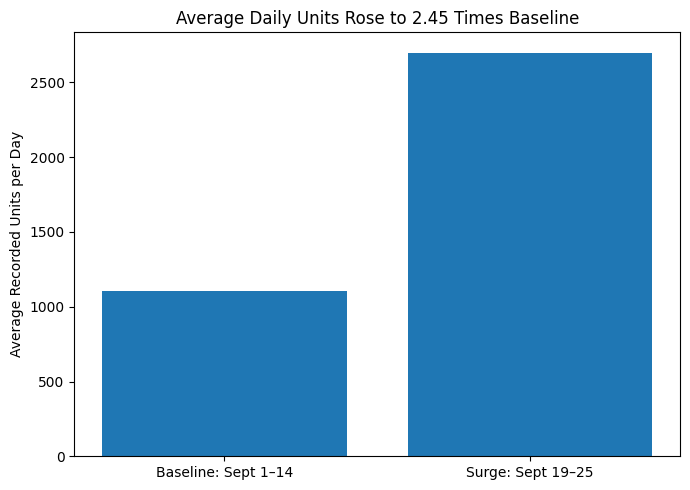

In [3]:
plt.figure(figsize=(7, 5))
plt.bar(
    ['Baseline: Sept 1–14', 'Surge: Sept 19–25'],
    [q1_baseline_avg, q1_surge_avg]
)
plt.title(f'Average Daily Units Rose to {q1_multiple:.2f} Times Baseline')
plt.ylabel('Average Recorded Units per Day')
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** Average daily recorded units increased from 1,104.07 during September 1–14, 2024, to 2,700.14 during September 19–25, 2024, reaching 2.45 times the baseline.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Original SKUs: 45
Canonical product families: 20
Units before consolidation: 49343
Units after consolidation: 49343
Unit totals preserved: True


,original_skus,total_units
canonical_product,,
Strawberry Pop-Tarts,4,5178
Bottled Water,3,5220
AA Batteries,3,4266
Monopoly,3,2006
LED Flashlight,2,2897
Canned Soup,2,2631
Emergency Candles,2,2595
Light Beer,2,2569
Playing Cards,2,2371


Largest family by number of SKUs: Strawberry Pop-Tarts
Before consolidation:
sku
POPTART-STRAW    1294
PT-12            1377
PT_STRAWBERRY    1254
SKU#459812       1253
Name: quantity, dtype: int64
After consolidation: 5178


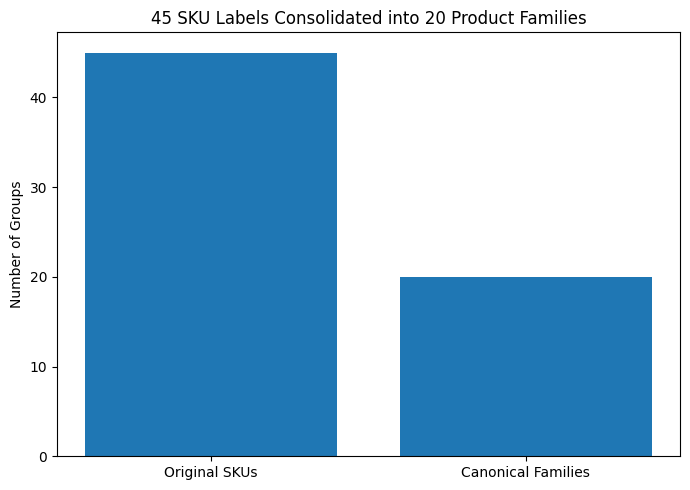

In [4]:

product_families = {
    'AA Batteries': ['BATT_AA_4PK', 'BAT-AA4', 'BATT-100'],
    'Bottled Water': ['WTR-24', 'WATER24PK', 'WTR_24PK'],
    'Diapers Size 3': ['DIAP-S3', 'DIAPERS-3'],
    'Baby Formula': ['BABYFORMULA', 'BFORM-01'],
    'Monopoly': ['GAME-MONO', 'MONOPOLY-01', 'BG-MONO'],
    'Emergency Candles': ['CNDL-EM', 'CANDLE-EMRG'],
    'Canned Soup': ['CNSOUP-01', 'SOUP-CAN'],
    'Chips Variety Pack': ['CHIPVARIETY', 'CHIPS-VP'],
    'LED Flashlight': ['FLASH-01', 'LED-FLASH'],
    'First Aid Kit': ['FIRSTAID-KIT', 'FAID-01'],
    'Heavy Duty Tarp': ['TARP-HD', 'HDTARP-01'],
    'Light Beer': ['LTBEER24', 'BEER-24'],
    'Peanut Butter': ['PB-16', 'PNUTBTR-16'],
    'Playing Cards': ['PLAYCARD-STD', 'CARDS-01'],
    'Portable Charger': ['CHRG-PORT', 'PORTCHARGER'],
    'Paper Towels': ['PAPERTOWEL6', 'PTOWEL-6'],
    'Strawberry Pop-Tarts': [
        'POPTART-STRAW', 'SKU#459812', 'PT_STRAWBERRY', 'PT-12'
    ],
    'Roku Streaming Device': ['STREAM-01', 'ROKU-STD'],
    'Toilet Paper': ['TP-12', 'TOILETPAPER12'],
    'White Bread': ['WHITEBREAD', 'BREAD-WH']
}

sku_mapping = {}

for product, skus in product_families.items():
    for sku in skus:
        sku_mapping[sku] = product

q2_transactions = walmart_transactions_copy.copy()
q2_transactions['canonical_product'] = (
    q2_transactions['sku'].map(sku_mapping)
)

assert q2_transactions['canonical_product'].notna().all()

q2_summary = q2_transactions.groupby('canonical_product').agg(
    original_skus=('sku', 'nunique'),
    total_units=('quantity', 'sum')
)

q2_summary = q2_summary.sort_values(
    ['original_skus', 'total_units'], ascending=False
)

q2_original_skus = q2_transactions['sku'].nunique()
q2_canonical_products = q2_transactions['canonical_product'].nunique()

units_before = walmart_transactions_copy['quantity'].sum()
units_after = q2_summary['total_units'].sum()

assert units_before == units_after

print('Original SKUs:', q2_original_skus)
print('Canonical product families:', q2_canonical_products)
print('Units before consolidation:', units_before)
print('Units after consolidation:', units_after)
print('Unit totals preserved:', units_before == units_after)

display(q2_summary)

# Show how the largest family by SKU count changes
largest_family = q2_summary.index[0]

before_comparison = (
    q2_transactions[
        q2_transactions['canonical_product'] == largest_family
    ]
    .groupby('sku')['quantity']
    .sum()
)

print('Largest family by number of SKUs:', largest_family)
print('Before consolidation:')
print(before_comparison)
print('After consolidation:', q2_summary.loc[largest_family, 'total_units'])

plt.figure(figsize=(7, 5))
plt.bar(
    ['Original SKUs', 'Canonical Families'],
    [q2_original_skus, q2_canonical_products]
)
plt.title('45 SKU Labels Consolidated into 20 Product Families')
plt.ylabel('Number of Groups')
plt.tight_layout()
plt.show()

**Q2 answer:** We consolidated 45 SKUs into 20 product families while preserving all 49,343 recorded units; Strawberry Pop-Tarts was the largest family by SKU count, combining four SKUs into 5,178 units, although conflicting package-size metadata means these are family totals without pack-size conversion.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

Weather obtained through live API calls; no fallback used.
Rows before weather join: 360
Rows after weather join: 360
Weather source: ['Open-Meteo archive API']
Missing pressure values: 0
Days in correlation: 30
Pressure-sales correlation: -0.281


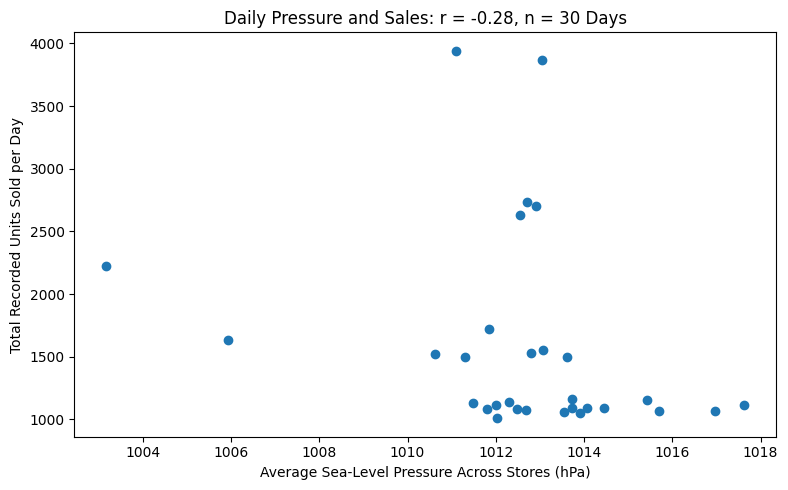

In [5]:
stores = pd.read_csv(base_url + 'store_locations.csv')
stores['store_id'] = clean_store_id(stores['store_id'])
stores = stores.drop_duplicates().copy()

stores.loc[
    stores['store_id'] == 'FL-619',
    ['latitude', 'longitude']
] = [30.4383, -84.2807]

assert not stores['store_id'].duplicated().any()
assert stores[['latitude', 'longitude']].notna().all().all()

url = 'https://archive-api.open-meteo.com/v1/archive'
weather_tables = []

for _, store in stores.iterrows():
    params = {
        'latitude': store['latitude'],
        'longitude': store['longitude'],
        'start_date': '2024-09-01',
        'end_date': '2024-09-30',
        'hourly': 'pressure_msl',
        'timezone': 'America/New_York'
    }

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()

    hourly = pd.DataFrame(response.json()['hourly'])
    hourly['date'] = pd.to_datetime(hourly['time']).dt.normalize()

    daily = (
        hourly.groupby('date')['pressure_msl']
        .mean()
        .reset_index(name='pressure_msl_mean')
    )

    daily['store_id'] = store['store_id']
    daily['source'] = 'Open-Meteo archive API'
    weather_tables.append(daily)

weather = pd.concat(weather_tables, ignore_index=True)

store_daily_sales = (
    q1_transactions.groupby(['store_id', 'transaction_date'])
    ['quantity'].sum()
    .reset_index(name='units')
    .rename(columns={'transaction_date': 'date'})
)

print('Weather obtained through live API calls; no fallback used.')

q3_joined = store_daily_sales.merge(
    weather,
    on=['store_id', 'date'],
    how='left',
    validate='many_to_one'
)

q3_join_rows_preserved = len(q3_joined) == len(store_daily_sales)

assert q3_join_rows_preserved
assert q3_joined['pressure_msl_mean'].notna().all()

print('Rows before weather join:', len(store_daily_sales))
print('Rows after weather join:', len(q3_joined))
print('Weather source:', q3_joined['source'].unique())
print('Missing pressure values:', q3_joined['pressure_msl_mean'].isna().sum())

q3_daily = q3_joined.groupby('date').agg(
    total_units=('units', 'sum'),
    average_pressure=('pressure_msl_mean', 'mean')
)

q3_days = len(q3_daily)
q3_correlation = q3_daily['total_units'].corr(
    q3_daily['average_pressure']
)

print('Days in correlation:', q3_days)
print('Pressure-sales correlation:', round(q3_correlation, 3))

plt.figure(figsize=(8, 5))
plt.scatter(q3_daily['average_pressure'], q3_daily['total_units'])
plt.xlabel('Average Sea-Level Pressure Across Stores (hPa)')
plt.ylabel('Total Recorded Units Sold per Day')
plt.title(f'Daily Pressure and Sales: r = {q3_correlation:.2f}, n = {q3_days} Days')
plt.tight_layout()
plt.show()

**Q3 answer, with its caveat:** Using historical weather retrieved through live Open-Meteo API calls with no fallback, we preserved all 360 store-day rows and found a weak negative correlation between average daily sea-level pressure across stores and total daily recorded units (r = −0.281 across 30 days); this short, single-month analysis excludes 884 transactions without timestamps and does not establish causation.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** Q4 (stores and geography): Store and regional comparisons and charts are already present, showing increased demand across all six regions; Norah is responsible for finishing this section, with Samikksha reviewing it.

**Q5 (signal or artifact):** The sales and inventory comparisons are already present, but the written percentages and interpretation still need to be reconciled with the outputs; Safaa is responsible for finishing this section, with Prabhnoor reviewing it.

### Self-check

In [7]:
progress = {
    'q1_multiple': q1_multiple,
    'q1_baseline_window': '2024-09-01 through 2024-09-14, inclusive',
    'q2_canonical_products': q2_canonical_products,
    'q3_join_rows_preserved': q3_join_rows_preserved,
    'q3_days_in_correlation': q3_days,
    'charts_with_message_titles': 3,
    'notebook_runs_clean': True,
    'repo_pushed': True,
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)

print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 2.4456233421750664
PASS - q1_baseline_window = 2024-09-01 through 2024-09-14, inclusive
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 3
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.
**b)** One number you reported that you are least confident in, and why.

a) One surprising finding was that Strawberry Pop-Tarts sales were split across four different SKUs. After mapping them to one product family, their combined recorded quantity was 5,178 units. We checked the individual SKU totals and used an assertion to verify that consolidation preserved the overall total of 49,343 recorded units. However, the catalog contains conflicting package sizes, so this comparison preserves recorded quantities without converting them into individual items.

b) We are least confident in the pressure-sales correlation of −0.281 because it is based on only 30 days from one month. Averaging pressure across 12 stores can hide local differences, and transactions with missing timestamps cannot be included. Shopping may also respond to forecasts before local pressure changes, so a same-day correlation may miss that timing and cannot establish causation.